# Fake News Classification Comparison

This notebook trains and compares three text-classification pipelines on the main dataset and evaluates them on an external validation dataset.

**Workflow**
1. Load the datasets
2. Clean and prepare the text
3. Split the main dataset into train and test sets
4. Train three models
5. Evaluate on the main test split
6. Evaluate on the validation dataset
7. Compare both results


## Imports


In [16]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

sns.set_style("whitegrid")


## Load datasets


In [17]:
df = pd.read_csv("data.csv")
validation_df = pd.read_csv("validation_data.csv")

print("Main dataset shape:", df.shape)
print("Validation dataset shape:", validation_df.shape)


Main dataset shape: (39942, 5)
Validation dataset shape: (4956, 5)


## Prepare text


In [18]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Main dataset
df["title"] = df["title"].astype(str)
df["text"] = df["text"].astype(str)
df["clean_text"] = (df["title"] + " " + df["text"]).apply(clean_text)

# Validation dataset — solo texto, SIN tocar labels
validation_df.columns = validation_df.columns.str.strip().str.lower()

if "title" not in validation_df.columns:
    validation_df["title"] = ""
if "text" not in validation_df.columns:
    fallback_cols = [c for c in validation_df.columns if c != "title"]
    validation_df["text"] = validation_df[fallback_cols].astype(str).agg(" ".join, axis=1)

validation_df["title"] = validation_df["title"].astype(str)
validation_df["text"] = validation_df["text"].astype(str)
validation_df["clean_text"] = (validation_df["title"] + " " + validation_df["text"]).apply(clean_text)

print("Validation dataset shape:", validation_df.shape)
print(validation_df["clean_text"].head(3))

Validation dataset shape: (4956, 6)
0    uk s may receiving regular updates on london t...
1    uk transport police leading investigation of l...
2    pacific nations crack down on north korean shi...
Name: clean_text, dtype: object


## Train/test split


In [19]:
X_text = df["clean_text"]
y = df["label"]

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Train size:", X_train_text.shape[0])
print("Test size:", X_test_text.shape[0])


Train size: 31953
Test size: 7989


## 1. TF-IDF + Logistic Regression


In [20]:
tfidf_lr_vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    max_features=5000
)

X_train_tfidf_lr = tfidf_lr_vectorizer.fit_transform(X_train_text)
X_test_tfidf_lr = tfidf_lr_vectorizer.transform(X_test_text)

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_tfidf_lr, y_train)

lr_pred = lr_model.predict(X_test_tfidf_lr)


## 2. Bag of Words + Naive Bayes


In [21]:
bow_nb_vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(1, 1),
    max_features=5000
)

X_train_bow_nb = bow_nb_vectorizer.fit_transform(X_train_text)
X_test_bow_nb = bow_nb_vectorizer.transform(X_test_text)

nb_model = MultinomialNB()
nb_model.fit(X_train_bow_nb, y_train)

nb_pred = nb_model.predict(X_test_bow_nb)


## 3. TF-IDF + Random Forest


In [22]:
tfidf_rf_vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 1),
    max_features=3000
)

X_train_tfidf_rf = tfidf_rf_vectorizer.fit_transform(X_train_text)
X_test_tfidf_rf = tfidf_rf_vectorizer.transform(X_test_text)

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_tfidf_rf, y_train)

rf_pred = rf_model.predict(X_test_tfidf_rf)


## Results on the main test split


In [23]:
results_main = pd.DataFrame({
    "Model": [
        "TF-IDF + Logistic Regression",
        "Bag of Words + Naive Bayes",
        "TF-IDF + Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, nb_pred),
        accuracy_score(y_test, rf_pred)
    ]
})

results_main


,Model,Accuracy
0,TF-IDF + Logistic Regression,0.987858
1,Bag of Words + Naive Bayes,0.943673
2,TF-IDF + Random Forest,0.997872


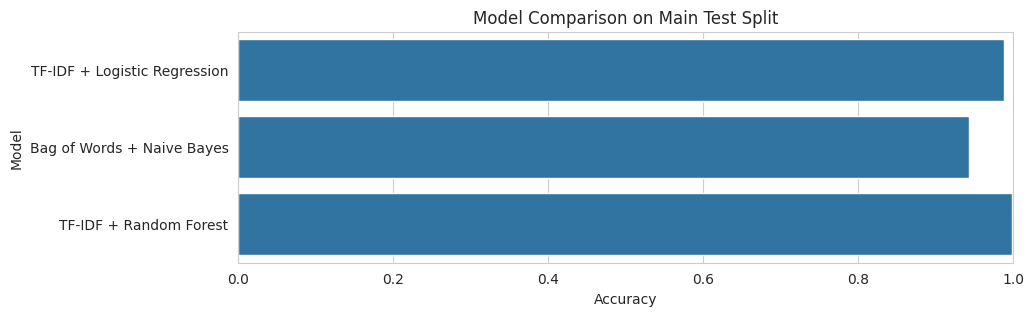

In [24]:
plt.figure(figsize=(10, 3))
sns.barplot(data=results_main, x="Accuracy", y="Model")
plt.title("Model Comparison on Main Test Split")
plt.xlabel("Accuracy")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.show()


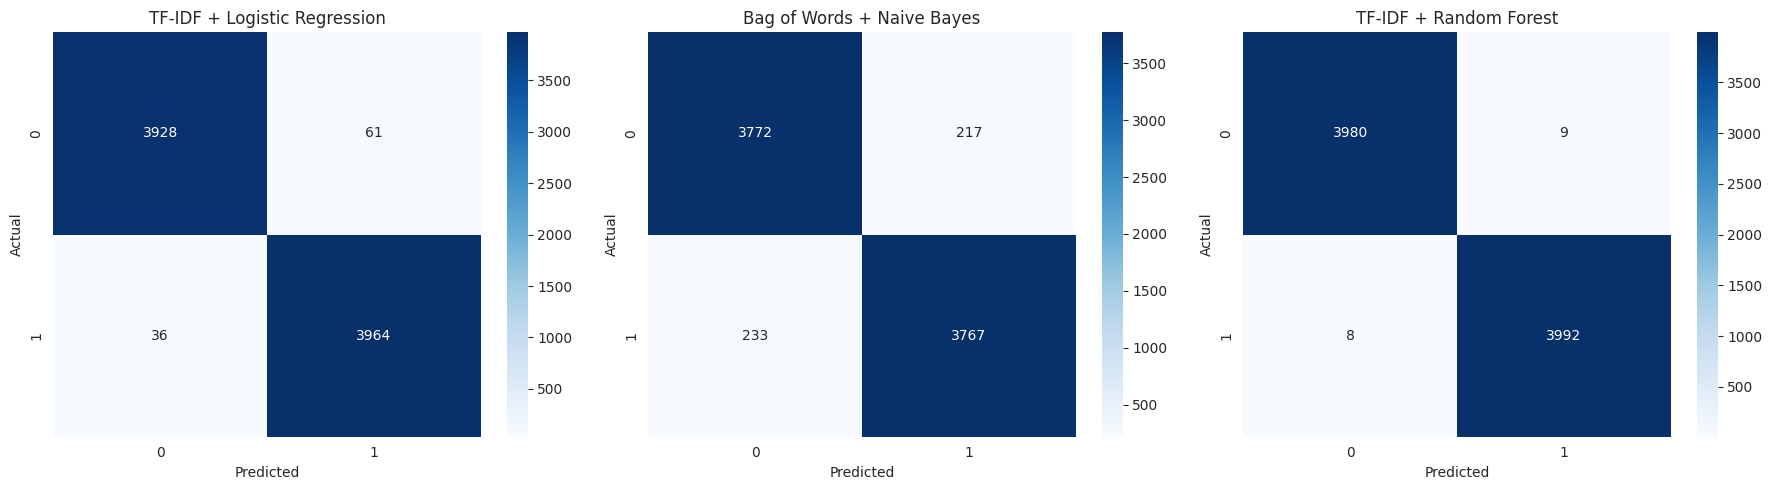

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cms_main = [
    confusion_matrix(y_test, lr_pred),
    confusion_matrix(y_test, nb_pred),
    confusion_matrix(y_test, rf_pred)
]

titles = [
    "TF-IDF + Logistic Regression",
    "Bag of Words + Naive Bayes",
    "TF-IDF + Random Forest"
]

for ax, cm, title in zip(axes, cms_main, titles):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


#Cross validation

We implement in order to make more robust our models

In [26]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

# Definir pipelines completos (vectorizer + modelo juntos)
pipeline_lr = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=(1, 2), max_features=5000)),
    ("clf", LogisticRegression(max_iter=1000, random_state=42))
])

pipeline_nb = Pipeline([
    ("bow", CountVectorizer(stop_words="english", ngram_range=(1, 1), max_features=5000)),
    ("clf", MultinomialNB())
])

pipeline_rf = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=(1, 1), max_features=3000)),
    ("clf", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))
])

# Cross-validation con 5 folds sobre TODO data.csv
X_all = df["clean_text"]
y_all = df["label"]

print("Running cross-validation (5 folds)... this may take a few minutes")

cv_lr = cross_val_score(pipeline_lr, X_all, y_all, cv=5, scoring="accuracy", n_jobs=-1)
cv_nb = cross_val_score(pipeline_nb, X_all, y_all, cv=5, scoring="accuracy", n_jobs=-1)
cv_rf = cross_val_score(pipeline_rf, X_all, y_all, cv=5, scoring="accuracy", n_jobs=-1)

results_cv = pd.DataFrame({
    "Model": [
        "TF-IDF + Logistic Regression",
        "Bag of Words + Naive Bayes",
        "TF-IDF + Random Forest"
    ],
    "CV Mean Accuracy": [cv_lr.mean(), cv_nb.mean(), cv_rf.mean()],
    "CV Std": [cv_lr.std(), cv_nb.std(), cv_rf.std()],
    "CV Min": [cv_lr.min(), cv_nb.min(), cv_rf.min()],
    "CV Max": [cv_lr.max(), cv_nb.max(), cv_rf.max()]
})

print(results_cv.to_string(index=False))

Running cross-validation (5 folds)... this may take a few minutes
                       Model  CV Mean Accuracy   CV Std   CV Min   CV Max
TF-IDF + Logistic Regression          0.977317 0.009444 0.959940 0.986106
  Bag of Words + Naive Bayes          0.912347 0.036988 0.839384 0.939284
      TF-IDF + Random Forest          0.997146 0.001999 0.993490 0.998999


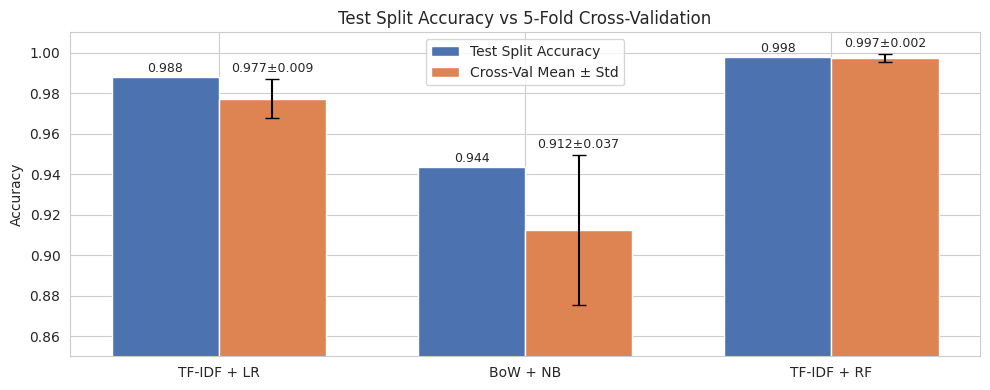

In [27]:
fig, ax = plt.subplots(figsize=(10, 4))

models_short = ["TF-IDF + LR", "BoW + NB", "TF-IDF + RF"]
cv_means = results_cv["CV Mean Accuracy"].values
cv_stds = results_cv["CV Std"].values
test_accs = results_main["Accuracy"].values

x = range(len(models_short))
width = 0.35

bars1 = ax.bar([i - width/2 for i in x], test_accs, width,
               label="Test Split Accuracy", color="#4C72B0")
bars2 = ax.bar([i + width/2 for i in x], cv_means, width,
               yerr=cv_stds, capsize=5,
               label="Cross-Val Mean ± Std", color="#DD8452")

ax.set_xticks(list(x))
ax.set_xticklabels(models_short)
ax.set_ylabel("Accuracy")
ax.set_ylim(0.85, 1.01)
ax.set_title("Test Split Accuracy vs 5-Fold Cross-Validation")
ax.legend()

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=9)
for bar, std in zip(bars2, cv_stds):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + std + 0.002,
            f"{bar.get_height():.3f}±{std:.3f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

## Evaluation on the validation dataset


In [28]:
X_val_tfidf_lr = tfidf_lr_vectorizer.transform(validation_df["clean_text"])
X_val_bow_nb = bow_nb_vectorizer.transform(validation_df["clean_text"])
X_val_tfidf_rf = tfidf_rf_vectorizer.transform(validation_df["clean_text"])

# Variables individuales para compatibilidad con celdas siguientes
lr_val_pred = lr_model.predict(X_val_tfidf_lr)
nb_val_pred = nb_model.predict(X_val_bow_nb)
rf_val_pred = rf_model.predict(X_val_tfidf_rf)

# Guardar en dataframe
validation_df["pred_lr"] = lr_val_pred
validation_df["pred_nb"] = nb_val_pred
validation_df["pred_rf"] = rf_val_pred

# Tabla de distribución de predicciones
results_validation = pd.DataFrame({
    "Model": [
        "TF-IDF + Logistic Regression",
        "Bag of Words + Naive Bayes",
        "TF-IDF + Random Forest"
    ],
    "Predicted Fake (0)": [
        (lr_val_pred == 0).sum(),
        (nb_val_pred == 0).sum(),
        (rf_val_pred == 0).sum()
    ],
    "Predicted Real (1)": [
        (lr_val_pred == 1).sum(),
        (nb_val_pred == 1).sum(),
        (rf_val_pred == 1).sum()
    ],
    "% Fake": [
        (lr_val_pred == 0).mean() * 100,
        (nb_val_pred == 0).mean() * 100,
        (rf_val_pred == 0).mean() * 100
    ]
})

print(results_validation)

                          Model  Predicted Fake (0)  Predicted Real (1)  \
0  TF-IDF + Logistic Regression                3376                1580   
1    Bag of Words + Naive Bayes                3056                1900   
2        TF-IDF + Random Forest                3500                1456   

      % Fake  
0  68.119451  
1  61.662631  
2  70.621469  


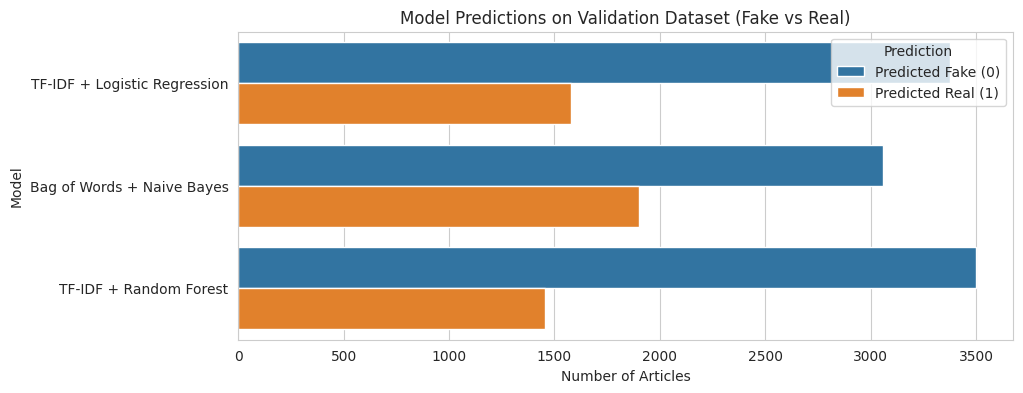

In [29]:
comparison_long = results_validation.melt(
    id_vars="Model",
    value_vars=["Predicted Fake (0)", "Predicted Real (1)"],
    var_name="Prediction",
    value_name="Count"
)

plt.figure(figsize=(10, 4))
sns.barplot(data=comparison_long, x="Count", y="Model", hue="Prediction")
plt.title("Model Predictions on Validation Dataset (Fake vs Real)")
plt.xlabel("Number of Articles")
plt.ylabel("Model")
plt.show()

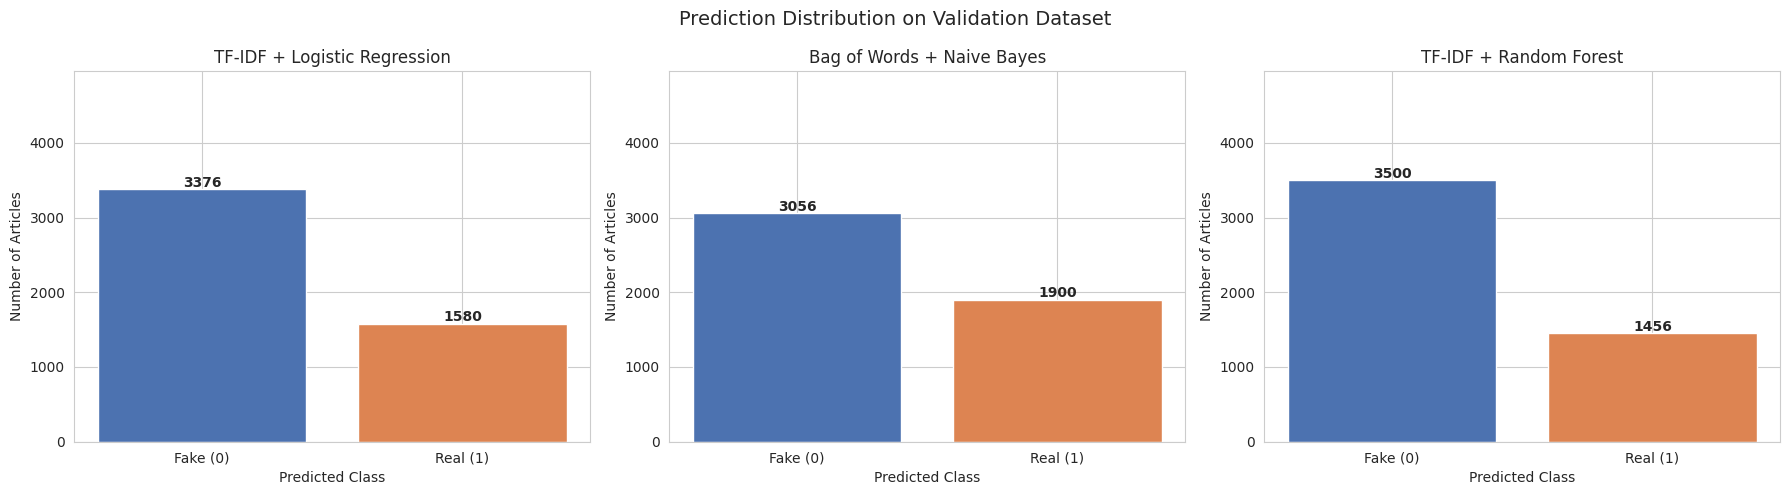

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

preds = [lr_val_pred, nb_val_pred, rf_val_pred]
titles = [
    "TF-IDF + Logistic Regression",
    "Bag of Words + Naive Bayes",
    "TF-IDF + Random Forest"
]
labels = ["Fake (0)", "Real (1)"]

for ax, pred, title in zip(axes, preds, titles):
    counts = pd.Series(pred).value_counts().reindex([0, 1], fill_value=0)
    ax.bar(labels, counts.values, color=["#4C72B0", "#DD8452"])
    ax.set_title(title)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Number of Articles")
    ax.set_ylim(0, len(lr_val_pred))
    for i, v in enumerate(counts.values):
        ax.text(i, v + 30, str(v), ha="center", fontweight="bold")

plt.suptitle("Prediction Distribution on Validation Dataset", fontsize=14)
plt.tight_layout()
plt.show()

## Main test split vs validation dataset


In [31]:
comparison_df = results_main.merge(
    results_validation[["Model", "% Fake"]],
    on="Model"
)
comparison_df = comparison_df.rename(columns={"% Fake": "% Fake Predicted (Validation)"})

comparison_df


,Model,Accuracy,% Fake Predicted (Validation)
0,TF-IDF + Logistic Regression,0.987858,68.119451
1,Bag of Words + Naive Bayes,0.943673,61.662631
2,TF-IDF + Random Forest,0.997872,70.621469


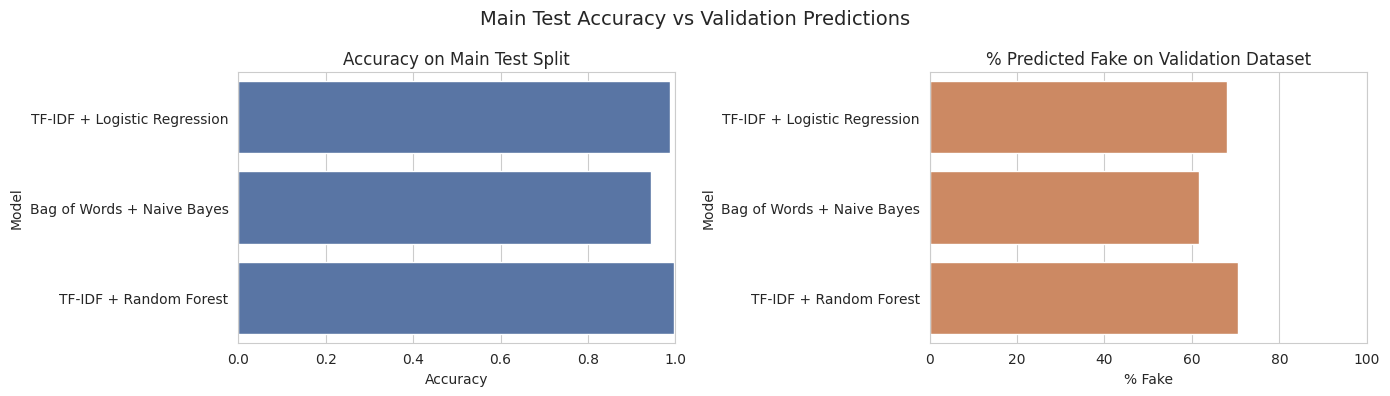

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Izquierda: Accuracy en test principal
sns.barplot(data=results_main, x="Accuracy", y="Model", ax=axes[0], color="#4C72B0")
axes[0].set_title("Accuracy on Main Test Split")
axes[0].set_xlabel("Accuracy")
axes[0].set_xlim(0, 1)

# Derecha: % predicho como Fake en validación
sns.barplot(data=results_validation, x="% Fake", y="Model", ax=axes[1], color="#DD8452")
axes[1].set_title("% Predicted Fake on Validation Dataset")
axes[1].set_xlabel("% Fake")
axes[1].set_xlim(0, 100)

plt.suptitle("Main Test Accuracy vs Validation Predictions", fontsize=14)
plt.tight_layout()
plt.show()
